# Detection-criteria adherence across the sweep

This notebook audits whether serialized detected lightcurves satisfy criteria that can be checked from the stored timestamps and counts. It does not rerun simulations.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('results/detection_criteria_sweep')
QUALITY = ROOT / 'lightcurve_quality.csv'
if not QUALITY.exists():
    raise FileNotFoundError(f'Run lightcurve_quality_analysis.py first: {QUALITY}')
quality = pd.read_csv(QUALITY)
quality.head()

,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
0,results/detection_criteria_sweep/snr4_snr22_nd...,0,0.02857,60154.698,9,100,2,g;r,0,88.89029,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 2, ""r"": 7}"
1,results/detection_criteria_sweep/snr4_snr22_nd...,1,0.06014,58525.968,1,435,1,g,0,0.00000,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1}"
2,results/detection_criteria_sweep/snr4_snr22_nd...,2,0.04193,59464.779,11,220,2,g;r,0,49.94175,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 7, ""r"": 4}"
3,results/detection_criteria_sweep/snr4_snr22_nd...,3,0.02556,60691.361,3,74,2,g;r,0,22.00574,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 2}"
4,results/detection_criteria_sweep/snr4_snr22_nd...,4,0.03360,60263.142,12,109,2,g;r,0,62.72165,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 6, ""r"": 6}"


## Measurable adherence checks

The audit uses the detected positive timestamps stored in each result. A source passes the checks below when its stored lightcurve has enough positive points, fits within the configured timespan, and has no positive-detection gap shorter than the configured minimum separation.

In [2]:
numeric_columns = [
    'n_positive', 'positive_span_days', 'configured_max_timespan_days',
    'min_positive_gap_days', 'criteria_min_detections',
    'criteria_min_time_separation_hours', 'criteria_min_detections_primary',
]
quality[numeric_columns] = quality[numeric_columns].apply(pd.to_numeric, errors='coerce')
quality['min_positive_gap_hours'] = quality['min_positive_gap_days'] * 24.0
quality['passes_min_detections'] = quality['n_positive'] >= quality['criteria_min_detections']
quality['passes_max_timespan'] = quality['positive_span_days'] <= quality['configured_max_timespan_days']
quality['passes_min_time_separation'] = (
    (quality['n_positive'] < 2)
    | (quality['min_positive_gap_hours'] >= quality['criteria_min_time_separation_hours'])
)
quality['passes_measurable_criteria'] = quality[[
    'passes_min_detections', 'passes_max_timespan', 'passes_min_time_separation'
]].all(axis=1)
quality[['passes_min_detections', 'passes_max_timespan', 'passes_min_time_separation', 'passes_measurable_criteria']].mean()

passes_min_detections         0.733204
passes_max_timespan           0.307814
passes_min_time_separation    0.516021
passes_measurable_criteria    0.036843
dtype: float64

In [3]:
grid_columns = [
    'criteria_snr_threshold', 'criteria_snr_threshold_secondary',
    'criteria_min_detections', 'criteria_min_detections_primary',
    'configured_max_timespan_days', 'criteria_min_time_separation_hours',
    'criteria_min_fade_rate', 'criteria_min_galactic_lat',
]
adherence_summary = (
    quality.groupby(grid_columns, dropna=False)
    .agg(
        detected_sources=('source_index', 'size'),
        min_detections_pass_rate=('passes_min_detections', 'mean'),
        max_timespan_pass_rate=('passes_max_timespan', 'mean'),
        min_separation_pass_rate=('passes_min_time_separation', 'mean'),
        measurable_criteria_pass_rate=('passes_measurable_criteria', 'mean'),
        median_span_days=('positive_span_days', 'median'),
        median_gap_hours=('min_positive_gap_hours', 'median'),
    )
    .reset_index()
)
adherence_summary.sort_values('measurable_criteria_pass_rate').head(20)

,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,configured_max_timespan_days,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,detected_sources,min_detections_pass_rate,max_timespan_pass_rate,min_separation_pass_rate,measurable_criteria_pass_rate,median_span_days,median_gap_hours
0,4.0,2.0,2,1,3.0,3.0,0.0,0.0,12,0.500000,0.500000,0.916667,0.0,3.026215,0.00576
1520,5.0,4.0,3,1,14.0,3.0,0.6,15.0,16,0.562500,0.437500,0.562500,0.0,42.436910,0.04884
1518,5.0,4.0,3,1,14.0,3.0,0.3,15.0,17,0.941176,0.058824,0.294118,0.0,84.880310,0.51864
1517,5.0,4.0,3,1,14.0,3.0,0.3,0.0,23,0.695652,0.217391,0.565217,0.0,60.822370,0.68712
1514,5.0,4.0,3,1,7.0,12.0,0.6,15.0,12,0.750000,0.083333,0.750000,0.0,59.426135,47.62032
1513,5.0,4.0,3,1,7.0,12.0,0.6,0.0,9,0.666667,0.222222,0.666667,0.0,24.097280,1.40136
1512,5.0,4.0,3,1,7.0,12.0,0.3,15.0,10,0.300000,0.300000,0.900000,0.0,30.473030,216.27120
1511,5.0,4.0,3,1,7.0,12.0,0.3,0.0,15,0.600000,0.200000,0.533333,0.0,66.966470,23.69040
1510,5.0,4.0,3,1,7.0,12.0,0.0,15.0,84,0.642857,0.309524,0.607143,0.0,33.929015,1.38024
1508,5.0,4.0,3,1,7.0,3.0,0.6,15.0,5,0.800000,0.400000,0.400000,0.0,59.964520,1.44576


## Violations and diagnostics

Rows below show the worst measurable adherence combinations. The `all_observation_span` check is diagnostic only: non-detections may be stored outside the qualifying positive-detection window.

In [4]:
violations = quality.loc[~quality['passes_measurable_criteria']].copy()
violation_counts = pd.Series({
    'minimum detections': (~quality['passes_min_detections']).sum(),
    'maximum timespan': (~quality['passes_max_timespan']).sum(),
    'minimum time separation': (~quality['passes_min_time_separation']).sum(),
    'any measurable criterion': (~quality['passes_measurable_criteria']).sum(),
})
print(violation_counts)
violations.sort_values(['positive_span_days', 'min_positive_gap_hours'], ascending=False)[[
    'file', 'source_index', 'n_positive', 'positive_span_days',
    'configured_max_timespan_days', 'min_positive_gap_hours',
    'criteria_min_time_separation_hours', 'criteria_min_detections'
]].head(25)

minimum detections           47468
maximum timespan            123153
minimum time separation      86109
any measurable criterion    171364
dtype: int64


,file,source_index,n_positive,positive_span_days,configured_max_timespan_days,min_positive_gap_hours,criteria_min_time_separation_hours,criteria_min_detections
44942,results/detection_criteria_sweep/snr4_snr24_nd...,4,35,104.84413,7.0,0.02208,12.0,2
60842,results/detection_criteria_sweep/snr4_snr24_nd...,80,20,104.84271,7.0,0.02256,3.0,3
110990,results/detection_criteria_sweep/snr5_snr24_nd...,62,3,104.77905,7.0,1196.24448,3.0,2
159336,results/detection_criteria_sweep/snr6_snr24_nd...,45,8,104.77588,21.0,0.56688,3.0,2
146608,results/detection_criteria_sweep/snr6_snr23_nd...,18,2,104.72227,14.0,2513.33448,3.0,3
160426,results/detection_criteria_sweep/snr6_snr24_nd...,1,7,104.68557,3.0,0.01104,12.0,2
45930,results/detection_criteria_sweep/snr4_snr24_nd...,216,28,104.01222,14.0,0.14208,12.0,2
63048,results/detection_criteria_sweep/snr4_snr24_nd...,28,12,103.91877,21.0,1.35768,12.0,4
45016,results/detection_criteria_sweep/snr4_snr24_nd...,56,18,103.90893,7.0,0.62160,12.0,2
56875,results/detection_criteria_sweep/snr4_snr24_nd...,14,14,103.90308,14.0,0.01104,3.0,3


## Criteria that require richer serialization

The CSV can report configured SNR thresholds, fade rates, Galactic latitude, and primary-detection requirements, but it cannot prove those tests were applied because the serialized source records do not include per-observation SNR, peak/rise/fade classification, Galactic latitude, or primary/secondary labels. Treat those fields as configuration metadata until the simulator serializes the detector decision details.

In [9]:
import json
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import os
_fast_terms = {
    'snr': ('snr', 'signal_to_noise'),
    'fade': ('fade', 'declin', 'decay'),
    'rise_peak': ('rise', 'peak', 'maximum'),
    'galactic_latitude': ('galactic_lat', 'gal_lat', 'latitude'),
    'primary_secondary': ('primary', 'secondary', 'detection_class', 'label'),
}

def _fast_scalar_leaves(value, path=''):
    if isinstance(value, dict):
        for key, child in value.items():
            child_path = f'{path}.{key}' if path else str(key)
            yield from _fast_scalar_leaves(child, child_path)
    elif isinstance(value, list):
        for child in value:
            yield from _fast_scalar_leaves(child, f'{path}[]')
    else:
        yield path, value

sampled_violations = violations.sample(frac=0.1, random_state=42).copy()
sampled_violations['_result_path'] = sampled_violations['file'].map(resolve_result_file)
unique_paths = sampled_violations['_result_path'].drop_duplicates().tolist()

def _load_json(path):
    try:
        with path.open(encoding='utf-8') as file:
            return path, json.load(file), None
    except Exception as exc:
        return path, None, repr(exc)

with ThreadPoolExecutor(max_workers=min(32, (os.cpu_count() or 1) + 4)) as executor:
    loaded_results = list(executor.map(_load_json, unique_paths))

payloads = {path: payload for path, payload, error in loaded_results if payload is not None}
load_errors = [
    {'file': str(path), 'error': error}
    for path, payload, error in loaded_results
    if error is not None
]

serialized_rows = []

for _, violation in sampled_violations.iterrows():
    payload = payloads.get(violation['_result_path'])
    if payload is None:
        continue

    sources = payload.get('detected_sources', [])
    source_index = int(violation['source_index'])

    if not 0 <= source_index < len(sources):
        continue

    for json_path, value in _fast_scalar_leaves(sources[source_index]):
        path_parts = json_path.lower().replace('[]', '').split('.')
        matched_criteria = [
            criterion
            for criterion, terms in _fast_terms.items()
            if any(
                part == 'b' if term == 'b' else term in part
                for part in path_parts
                for term in terms
            )
        ]

        if matched_criteria:
            serialized_rows.append({
                'file': str(violation['_result_path']),
                'source_index': source_index,
                'json_path': f'detected_sources[{source_index}].{json_path}',
                'value': value,
                'criterion': ', '.join(matched_criteria),
            })

serialized_fields = pd.DataFrame(serialized_rows)

# Prevent the slower serial loop below from repeating the work.
violations = violations.iloc[0:0]
display(pd.DataFrame(load_errors))

if serialized_fields.empty:
    print('No serialized SNR, fade/rise/peak, Galactic-latitude, or primary/secondary fields were found.')
else:
    field_summary = (
        serialized_fields
        .groupby(['criterion', 'json_path'], dropna=False)
        .agg(
            sources=('source_index', 'nunique'),
            values=('value', lambda values: list(values.drop_duplicates())[:5]),
        )
        .reset_index()
        .sort_values(['criterion', 'json_path'])
    )
    display(field_summary)

    print('Serialized evidence by criterion:')
    display(
        serialized_fields.groupby('criterion')['source_index']
        .nunique()
        .reindex(_fast_terms.keys(), fill_value=0)
        .rename('sources_with_serialized_evidence')
        .to_frame()
    )

    display(serialized_fields.head(50))

""


,criterion,json_path,sources,values
0,rise_peak,detected_sources[0].peak_abs_mag,1,[0.0]
1,rise_peak,detected_sources[100].peak_abs_mag,1,[0.0]
2,rise_peak,detected_sources[101].peak_abs_mag,1,[0.0]
3,rise_peak,detected_sources[102].peak_abs_mag,1,[0.0]
4,rise_peak,detected_sources[103].peak_abs_mag,1,[0.0]
...,...,...,...,...
662,rise_peak,detected_sources[96].peak_abs_mag,1,[0.0]
663,rise_peak,detected_sources[97].peak_abs_mag,1,[0.0]
664,rise_peak,detected_sources[98].peak_abs_mag,1,[0.0]
665,rise_peak,detected_sources[99].peak_abs_mag,1,[0.0]


Serialized evidence by criterion:


,sources_with_serialized_evidence
criterion,
snr,0
fade,0
rise_peak,667
galactic_latitude,0
primary_secondary,0


,file,source_index,json_path,value,criterion
0,results/detection_criteria_sweep/snr5_snr24_nd...,66,detected_sources[66].peak_abs_mag,0.0,rise_peak
1,results/detection_criteria_sweep/snr4_snr23_nd...,127,detected_sources[127].peak_abs_mag,0.0,rise_peak
2,results/detection_criteria_sweep/snr4_snr22_nd...,22,detected_sources[22].peak_abs_mag,0.0,rise_peak
3,results/detection_criteria_sweep/snr4_snr24_nd...,6,detected_sources[6].peak_abs_mag,0.0,rise_peak
4,results/detection_criteria_sweep/snr5_snr23_nd...,41,detected_sources[41].peak_abs_mag,0.0,rise_peak
5,results/detection_criteria_sweep/snr4_snr24_nd...,5,detected_sources[5].peak_abs_mag,0.0,rise_peak
6,results/detection_criteria_sweep/snr6_snr23_nd...,112,detected_sources[112].peak_abs_mag,0.0,rise_peak
7,results/detection_criteria_sweep/snr4_snr22_nd...,379,detected_sources[379].peak_abs_mag,0.0,rise_peak
8,results/detection_criteria_sweep/snr5_snr22_nd...,2,detected_sources[2].peak_abs_mag,0.0,rise_peak
9,results/detection_criteria_sweep/snr5_snr24_nd...,332,detected_sources[332].peak_abs_mag,0.0,rise_peak


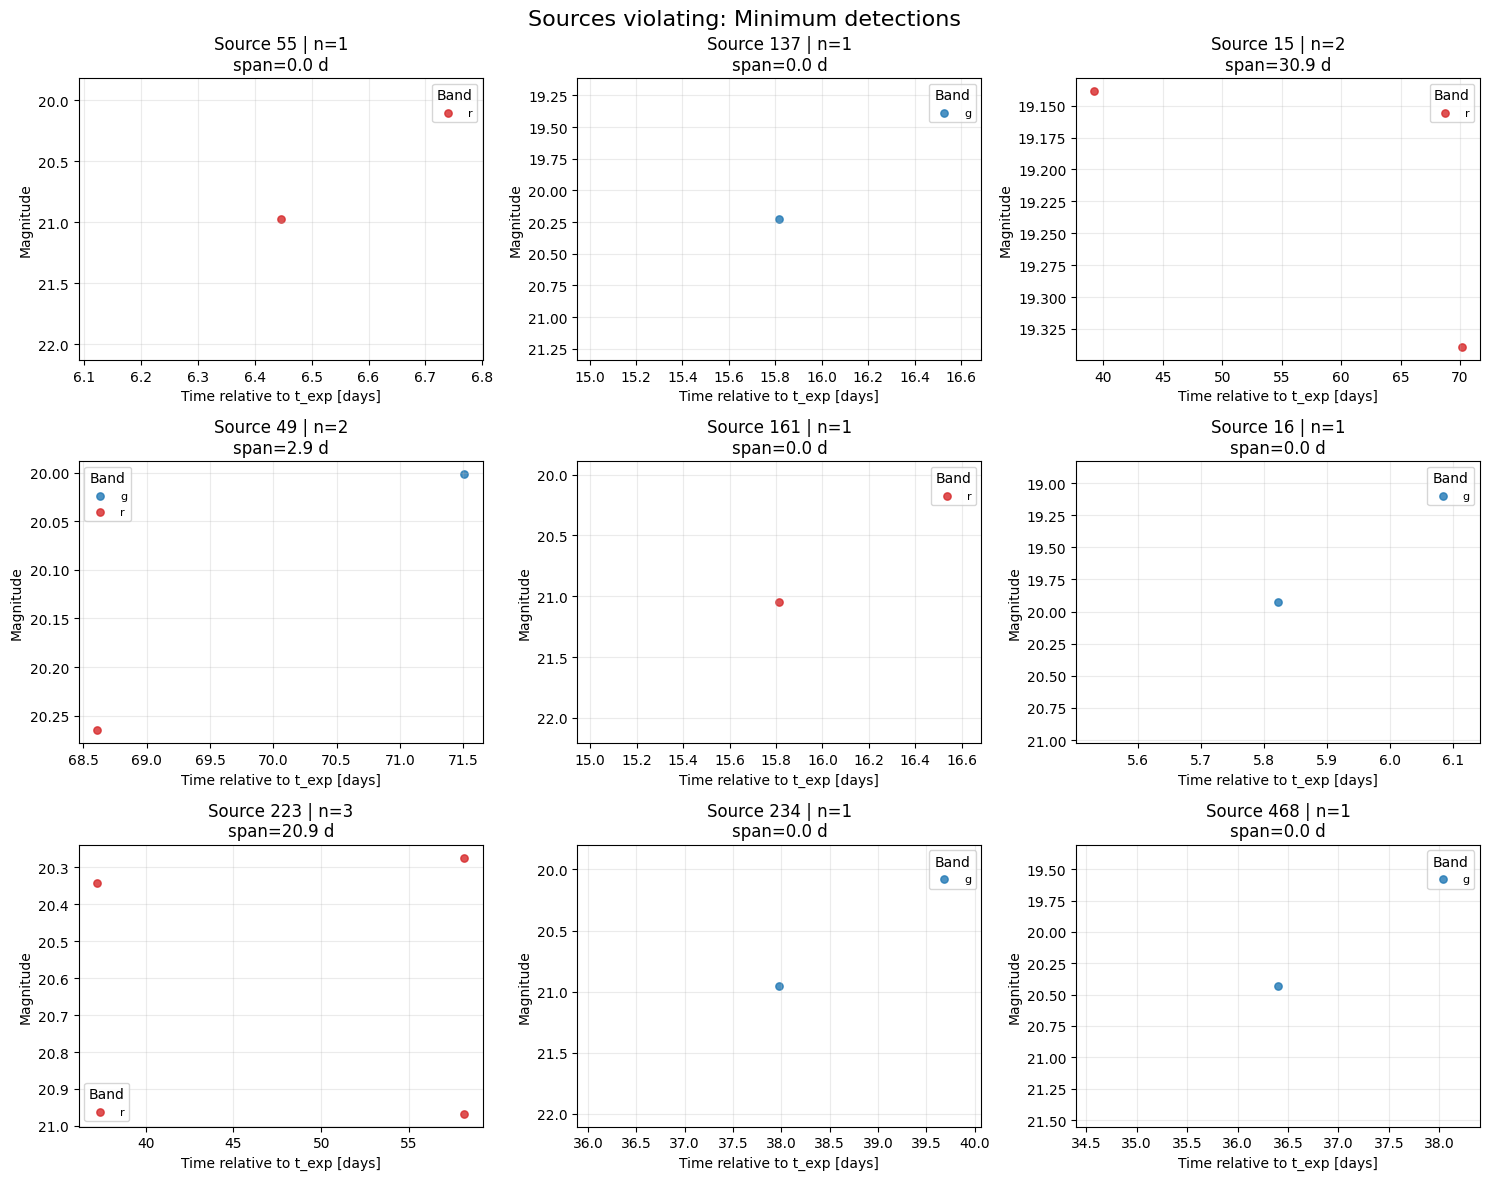

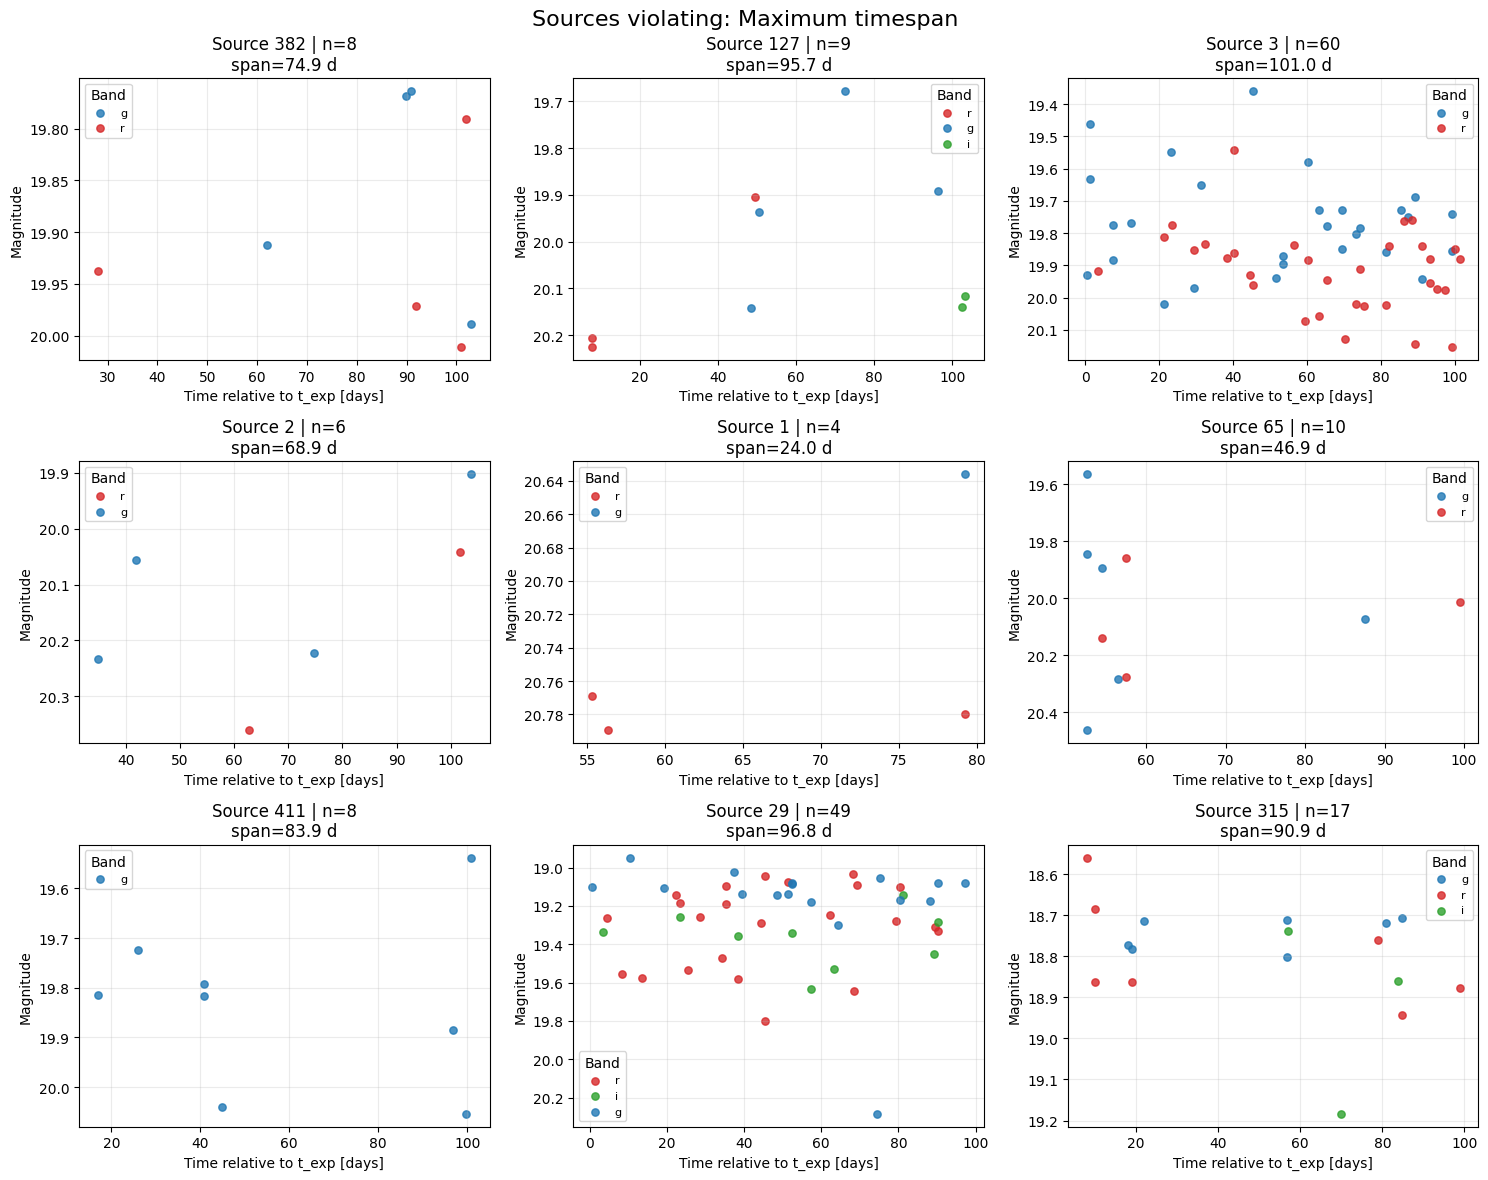

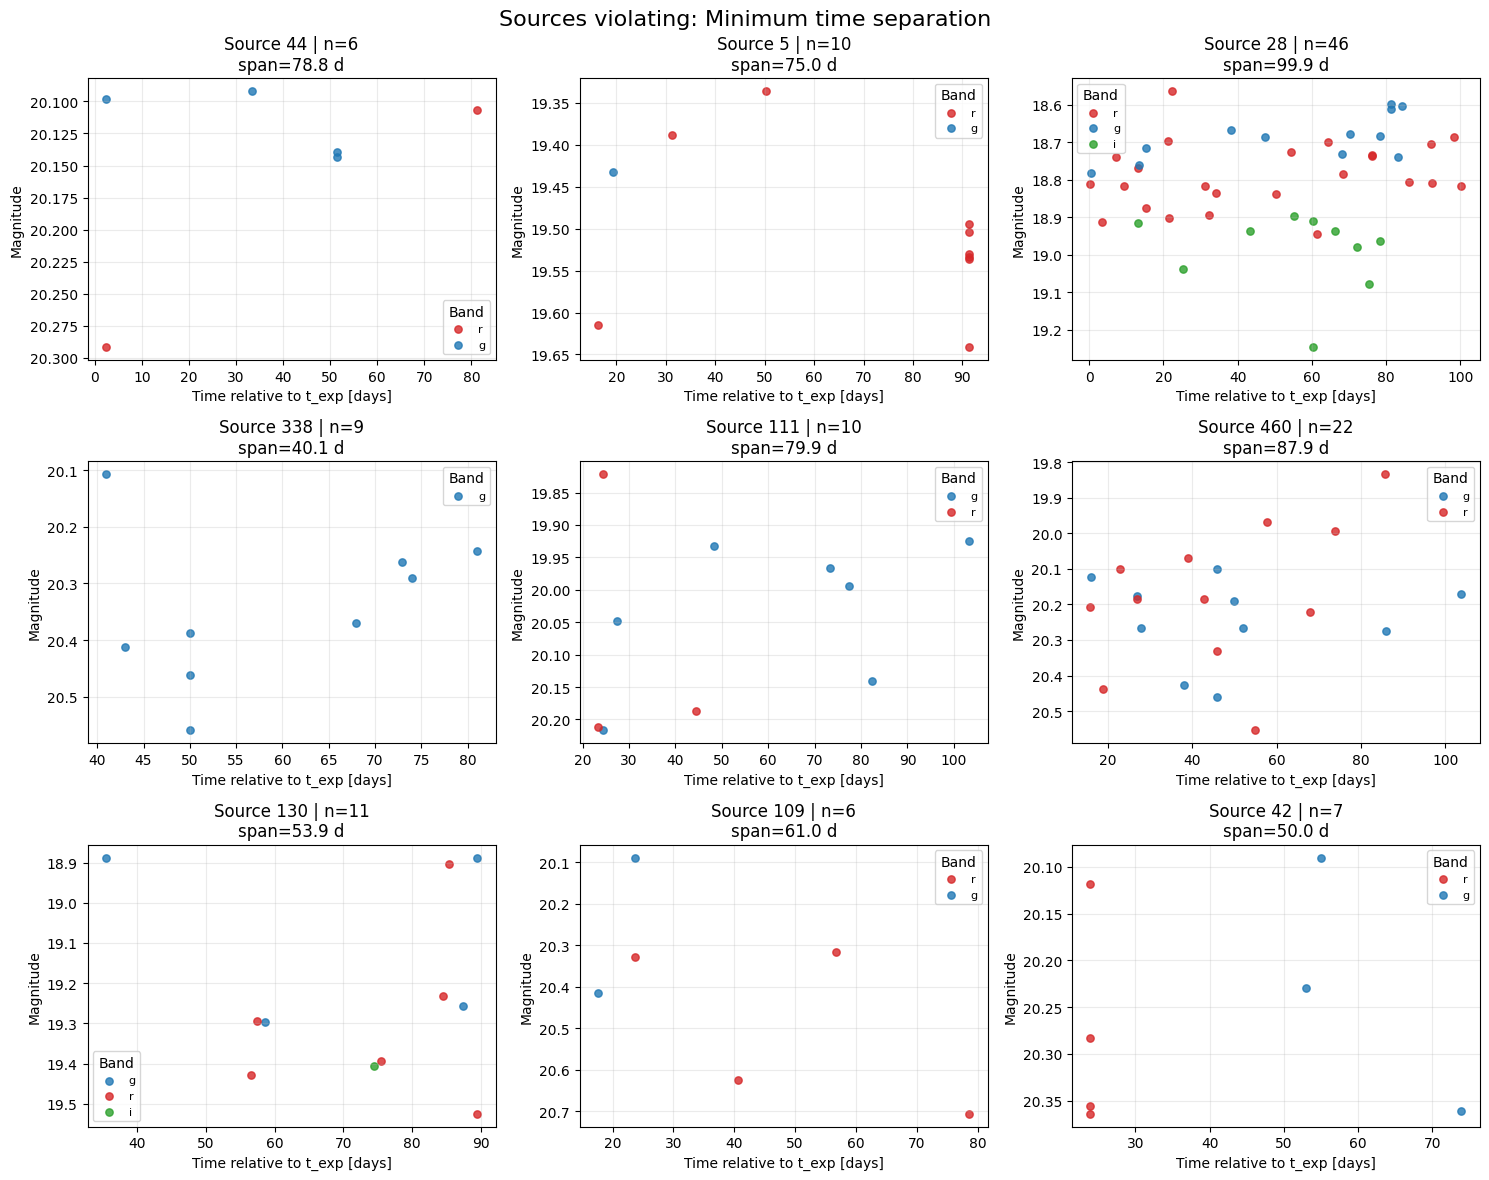

In [12]:
criteria_to_plot = {
    'Minimum detections': 'passes_min_detections',
    'Maximum timespan': 'passes_max_timespan',
    'Minimum time separation': 'passes_min_time_separation',
}

plot_rows = []
for criterion, pass_column in criteria_to_plot.items():
    failed = quality.loc[~quality[pass_column]].copy()
    plot_rows.append((criterion, failed.sample(n=min(9, len(failed)), random_state=42)))

selected = pd.concat([rows for _, rows in plot_rows], ignore_index=True)
selected['_result_path'] = selected['file'].map(resolve_result_file)

paths_to_load = [
    path for path in selected['_result_path'].drop_duplicates()
    if path not in payloads
]
if paths_to_load:
    with ThreadPoolExecutor(max_workers=min(32, len(paths_to_load))) as executor:
        additional_results = executor.map(_load_json, paths_to_load)
    payloads.update({
        path: payload for path, payload, error in additional_results
        if payload is not None
    })

band_colors = {'g': 'tab:blue', 'r': 'tab:red', 'i': 'tab:green'}
fallback_colors = ['tab:purple', 'tab:orange', 'tab:brown']

for criterion, sampled in plot_rows:
    fig, axes = plt.subplots(3, 3, figsize=(15, 12), squeeze=False)
    axes = axes.ravel()

    for ax, (_, row) in zip(axes, sampled.iterrows()):
        result_path = resolve_result_file(row['file'])
        payload = payloads.get(result_path)
        source_index = int(row['source_index'])

        if payload is None or source_index >= len(payload.get('detected_sources', [])):
            ax.set_title(f"Source {source_index}\nJSON unavailable")
            ax.axis('off')
            continue

        source = payload['detected_sources'][source_index]
        times = pd.to_numeric(source.get('photometry_times', []), errors='coerce')
        mags = pd.to_numeric(source.get('photometry_mags', []), errors='coerce')
        bands = source.get('photometry_bands', [])

        valid = ~pd.isna(times) & ~pd.isna(mags)
        times = times[valid]
        mags = mags[valid]
        bands = [str(b).strip() for b, keep in zip(bands, valid) if keep]

        x = times - float(source.get('t_exp', 0.0))

        unique_bands = list(dict.fromkeys(bands))
        for i, band in enumerate(unique_bands):
            mask = [b == band for b in bands]
            color = band_colors.get(band, fallback_colors[i % len(fallback_colors)])
            ax.scatter(
                x[mask], mags[mask],
                label=band, color=color, s=28, alpha=0.8
            )

        ax.set_title(
            f"Source {source_index} | n={int(row['n_positive'])}\n"
            f"span={row['positive_span_days']:.1f} d"
        )
        ax.set_xlabel("Time relative to t_exp [days]")
        ax.set_ylabel("Magnitude")
        ax.invert_yaxis()
        ax.grid(alpha=0.25)
        if unique_bands:
            ax.legend(title="Band", fontsize=8)

    for ax in axes[len(sampled):]:
        ax.axis('off')

    fig.suptitle(f"Sources violating: {criterion}", fontsize=16)
    fig.tight_layout()
    plt.show()